<a href="https://colab.research.google.com/github/pattygirl665-lab/Wu_MA289_SVM_Spoken_Digit_Classification_67/blob/main/MA289_SVM_Mentor_Notes_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MA289 Competition 2 — Spoken Digits 6 vs. 7
**Beginner-friendly Google Colab notebook**

We predict the probability that each recording is **7** (label `1`). A **6** has label `0`. We will use SVM classifiers only, per the competition requirement.

**How to run:** In Google Colab, select **Runtime → Run all**, or run one cell at a time with the play button. When prompted, upload `train.csv`, `test.csv`, and `sample_submission.csv`.

This notebook uses: **train/validation separation**, **feature scaling**, **PCA**, **SVM comparison**, **ROC AUC**, then exports `submission.csv`.


## Step 1 — Import our Python tools
Libraries are bundles of code that let us work with data and machine learning. Colab normally includes these packages already.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, RocCurveDisplay, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42  # Makes the random split reproducible
print("Libraries loaded!")

Libraries loaded!


## Step 2 — Upload and read your CSV files
Use the upload window to select all three CSV files. `pd.read_csv` turns CSV files into tables called **DataFrames**.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Define the base path to your Google Drive folder
drive_folder_path = '/content/drive/MyDrive/Wu Colab Notebooks/Spoken Digit Data Competition' # Updated folder path

# Load the datasets

train = pd.read_csv(f'{drive_folder_path}/train.csv')
test = pd.read_csv(f'{drive_folder_path}/test.csv')
sample = pd.read_csv(f'{drive_folder_path}/sample_submission.csv')

In [ ]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Submission example shape:", sample.shape)
display(train.iloc[:5, :8])
print("Training labels:")
print(train["Label"].value_counts())

Train shape: (400, 16386)
Test shape: (200, 16385)
Submission example shape: (200, 2)


,ID,x0,x1,x2,x3,x4,x5,x6
0,1,181.0,181.0,181.0,255.0,181.0,181.0,181.0
1,2,223.0,223.0,223.0,255.0,223.0,223.0,223.0
2,3,189.0,189.0,189.0,255.0,189.0,189.0,189.0
3,4,155.0,155.0,155.0,255.0,155.0,155.0,155.0
4,5,170.0,170.0,170.0,255.0,170.0,170.0,170.0


Training labels:
Label
0    200
1    200
Name: count, dtype: int64


## Step 3 — Features (`X`) and labels (`y`): use −1/+1 for SVM

Your mentor is correct: in the **mathematical formulation** of SVM, binary classes are commonly encoded **−1 and +1**.

| Actual sound | Competition label | SVM training label |
|---|---:|---:|
| Six | `0` | `-1` |
| Seven | `1` | `+1` |

The 16,384 `x` columns are input features; `ID` is an identifier, **not** a feature. We save the competition's original labels too, because the output must be probabilities of **7** (class `1`). Scikit-learn `SVC` works with 0/1 labels, but we explicitly recode to connect the code to the theory.


In [ ]:
feature_cols = [col for col in train.columns if col.startswith("x")]
assert feature_cols == [col for col in test.columns if col.startswith("x")], "Feature columns do not match!"
assert train["Label"].isin([0, 1]).all(), "Expected competition labels 0/1"

X = train[feature_cols].astype("float32")
y_original = train["Label"].astype(int)  # Competition encoding: 0 = six, 1 = seven
y = y_original.replace({0: -1, 1: 1})  # SVM theory encoding: -1 = six, +1 = seven
X_competition = test[feature_cols].astype("float32")

print("Number of audio features:", len(feature_cols))
print("Original competition labels:", sorted(y_original.unique()))
print("SVM labels:", sorted(y.unique()))
print("Example pairs:")
display(pd.DataFrame({"Competition label": y_original.head(), "SVM label": y.head()}))
print("Missing features?", X.isna().any().any() or X_competition.isna().any().any())


Number of audio features: 16384
Original competition labels: [np.int64(0), np.int64(1)]
SVM labels: [np.int64(-1), np.int64(1)]
Example pairs:


,Competition label,SVM label
0,0,-1
1,1,1
2,1,1
3,0,-1
4,1,1


Missing features? False


## Step 4 — Separate training and validation data
Reserve 20% of the labeled data to simulate a final exam. **Do not train on this validation portion.** The `stratify=y` option makes both sets contain similar proportions of sixes and sevens.

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

Training rows: 320
Validation rows: 80


## Step 5 — Build a soft-margin SVM pipeline

**Mentor's geometry:** The SVM learns a dividing boundary

\[f(x)=\beta_0+\sum_{j=1}^p\beta_j x_j\]

- **Prediction:** `f(x) > 0` suggests `+1` (seven); `f(x) < 0` suggests `−1` (six).
- **Margin:** Aim for a wide gap between the two groups.
- **Support vectors:** Recordings closest to, within, or violating the margin are especially important in determining the boundary.
- **Slack / violations:** Real speech varies. A **soft-margin** SVM allows some points inside the margin or on the wrong side rather than requiring perfect separation.

For a common equivalent optimization form, SVM minimizes

\[\frac12\|w\|^2 + C\sum_i\max(0,1-y_i(w^T x_i+b))\]

Here, the second term penalizes margin violations (hinge loss). **scikit-learn's `C` is the penalty strength:**

| `C` | Effect |
|---|---|
| Small, e.g. `0.1` | Allows more violations, stronger regularization; can underfit |
| Large, e.g. `10` | Penalizes violations more, tries harder to fit training data; can overfit |

**Important:** Your mentor's notes describe a different formulation where `C` is the *allowed total slack*. In **scikit-learn, larger `C` means a *greater penalty* on slack**, not more tolerated violations. The formulations use different parameter definitions and the numerical values are not interchangeable.

**Pipeline:** We scale the feature values, optionally reduce feature dimension using PCA, scale the PCA components, then fit the SVM. Putting preprocessing inside the pipeline prevents the validation fold from leaking information into training.

We try **linear** and **RBF** kernels (the RBF kernel can learn nonlinear boundaries). Verify with your instructor that PCA and the RBF kernel are among the methods permitted in your class.


## Theory checkpoint: what does slack (ε) mean?

Your handwritten expression is close to a *soft-margin* constraint:

\[y_i(\beta_0+\beta^T x_i)\ge M(1-\epsilon_i),\qquad \epsilon_i\ge 0\]

Assuming a positive margin `M`:

- `ε = 0`: example satisfies the full margin.
- `0 < ε < 1`: example is correctly classified but lies **inside** the margin.
- `ε = 1`: the constraint allows it to be **on** the decision boundary.
- `ε > 1`: the constraint permits a point to be **misclassified** (though its exact location depends on its margin value).

This explains why slack can help with noisy recordings or unusual pronunciations. The SVM tries to balance a wide margin against too many violations, and `C` controls that tradeoff in scikit-learn's implementation.


In [ ]:
pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=40, svd_solver="randomized", random_state=RANDOM_STATE)),
    ("scale_pca", StandardScaler()),
    ("svm", SVC(probability=True, random_state=RANDOM_STATE))
])

# We compare linear and RBF SVMs using a few settings.
# C balances training mistakes versus a more flexible decision boundary.
# RBF can learn curved / nonlinear boundaries.
parameter_options = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10], "svm__gamma": ["scale"]}
]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_options,
    scoring="roc_auc",  # This matches the competition scoring metric
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

search.fit(X_train, y_train)
print("Best SVM settings:", search.best_params_)
print("Best average cross-validation ROC AUC:", round(search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best SVM settings: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best average cross-validation ROC AUC: 0.9999


## Step 6 — Compare SVM settings using cross-validation

We use three-fold cross-validation **within the training portion only**, saving the validation portion untouched until Step 7. `GridSearchCV` tries all listed options and chooses the best average ROC AUC. ROC AUC treats the **larger label (`+1`) as positive**, which represents *seven*.

`SVC(probability=True)` fits an additional probability calibration internally. This is why we can submit probabilities between 0 and 1 instead of merely `−1` or `+1` predictions.

**Timing note:** 16,384 columns make even this small dataset relatively high-dimensional. The PCA step reduces the dimension to 40 components. This is a practical baseline, not necessarily the optimal number.


In [ ]:
comparison = pd.DataFrame(search.cv_results_)[
    ["param_svm__kernel", "param_svm__C", "mean_test_score", "std_test_score"]
].sort_values("mean_test_score", ascending=False)
comparison.columns = ["Kernel", "C", "Mean CV AUC", "CV AUC Std Dev"]
display(comparison.reset_index(drop=True))

,Kernel,C,Mean CV AUC,CV AUC Std Dev
0,rbf,1.0,0.999884,0.000165
1,rbf,10.0,0.999767,0.000165
2,linear,10.0,0.998134,0.001898
3,linear,1.0,0.998134,0.001898
4,linear,0.1,0.998020,0.002557
5,rbf,0.1,0.997548,0.002748


## Step 7 — Evaluate on untouched validation data

We want **probability of `+1` (seven)**. Never assume an output column without checking `best_model.classes_`: `predict_proba` columns follow that class order.

We translate the labels back to `0`/`1` for an intuitive ROC AUC evaluation and confusion matrix. **Do not select settings based repeatedly on your validation score**: cross-validation already chose them, and this set is an independent check.


Probability column order: [-1  1]
Validation ROC AUC: 0.9969


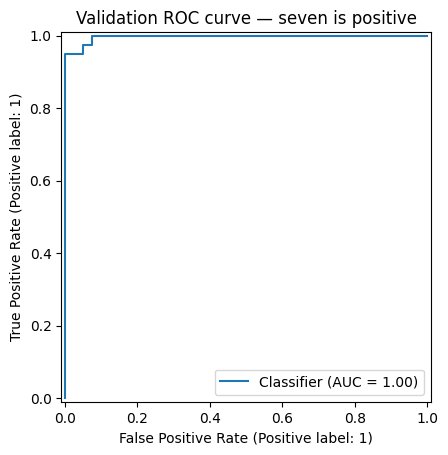

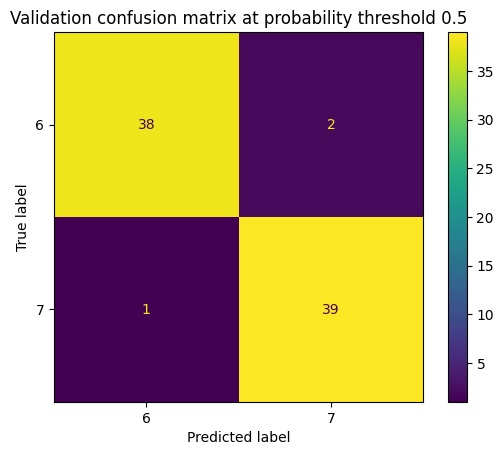

In [ ]:
best_model = search.best_estimator_
print("Probability column order:", best_model.classes_)  # Expect [-1, +1]
seven_col = list(best_model.classes_).index(1)
valid_prob = best_model.predict_proba(X_valid)[:, seven_col]
valid_auc = roc_auc_score((y_valid == 1).astype(int), valid_prob)
print("Validation ROC AUC:", round(valid_auc, 4))

RocCurveDisplay.from_predictions((y_valid == 1).astype(int), valid_prob)
plt.title("Validation ROC curve — seven is positive")
plt.show()

valid_pred = np.where(valid_prob >= 0.5, 1, -1)
ConfusionMatrixDisplay.from_predictions(y_valid, valid_pred, labels=[-1, 1], display_labels=["6", "7"])
plt.title("Validation confusion matrix at probability threshold 0.5")
plt.show()


## Step 8 — Train on every labeled recording
After evaluation, the model is fitted again on all **400 labeled recordings**. We reuse the SVM settings selected from the earlier cross-validation; the competition test labels remain unknown.

In [ ]:
final_model = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=40, svd_solver="randomized", random_state=RANDOM_STATE)),
    ("scale_pca", StandardScaler()),
    ("svm", SVC(
        kernel=search.best_params_["svm__kernel"],
        C=search.best_params_["svm__C"],
        gamma=search.best_params_.get("svm__gamma", "scale"),
        probability=True,
        random_state=RANDOM_STATE
    ))
])
final_model.fit(X, y)
print("Final model trained on", len(X), "rows")

Final model trained on 400 rows


## Step 9 — Predict probabilities on the competition test set

We are **not** submitting `−1` / `+1` labels. We submit the predicted **probability of `+1`**, which is the spoken digit **7**, for every competition test recording.


In [ ]:
# Locate the actual class +1 column (seven) by its label, not by assumption.
seven_col = list(final_model.classes_).index(1)
test_prob = final_model.predict_proba(X_competition)[:, seven_col]
submission = pd.DataFrame({"ID": test["ID"], "Probability": test_prob})

assert list(submission.columns) == ["ID", "Probability"]
assert len(submission) == len(test)
assert submission["ID"].reset_index(drop=True).equals(test["ID"].reset_index(drop=True))
assert submission["Probability"].between(0, 1).all()
assert not submission.isna().any().any()
assert submission["ID"].tolist() == sample["ID"].tolist(), "Test ID order differs from sample submission"

display(submission.head())
print("All submission checks passed!")


,ID,Probability
0,401,0.001592
1,402,0.008045
2,403,0.905661
3,404,0.931759
4,405,1.000000


All submission checks passed!


## Step 10 — Save and download your submission
This creates the required CSV without an extra row-number column. **Upload `submission.csv` to the competition**, not your notebook.

In [ ]:
submission.to_csv("submission.csv", index=False)
files.download("submission.csv")

submission_file_path = f'{drive_folder_path}/submission.csv'
submission.to_csv(submission_file_path, index=False)
print(f"Draft submission file saved to: {submission_file_path}")
print("Preview of submission with corrected 'ID' column:")
display(submission.head())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Draft submission file saved to: /content/drive/MyDrive/Wu Colab Notebooks/Spoken Digit Data Competition/submission.csv
Preview of submission with corrected 'ID' column:


,ID,Probability
0,401,0.001592
1,402,0.008045
2,403,0.905661
3,404,0.931759
4,405,1.000000


## Extra: connect your mentor's theory to your model

- **`X`** is a 400 × 16,384 table of numbers representing recordings. A row is one recording; a column is one audio feature.
- **`y`** is the known class: `−1` for six, `+1` for seven.
- **`β` / `w`** describes the orientation of a linear separating hyperplane; **`β₀` / `b`** is its intercept.
- **A support vector** is a training example that has influence on the SVM boundary. It need not be only the two nearest recordings; in high dimensions many can be support vectors.
- **Slack** means the algorithm permits certain points to be within the margin or misclassified.
- **`C` in scikit-learn** is a **penalty on violations**; a higher number means a stronger penalty.
- **Kernel** defines a similarity function used by SVM. Linear is a straight boundary in feature space; RBF can produce more complex boundaries.
- **ROC AUC** rewards assigning larger probabilities to actual sevens than actual sixes.
- **Final competition predictions** use probabilities of **seven**, not the theoretical SVM label `+1` itself.

### Common mistake to avoid

Do **not** use the competition test file to tune model hyperparameters: it has no true labels and is meant for final prediction only. Scale and fit PCA **within** the training folds via the pipeline, as the notebook does.


In [ ]:
# Select only the numeric sound features
feature_columns = [
    col for col in train.columns
    if col.startswith("x") and col[1:].isdigit()
]

X = train[feature_columns]
X_test = test[feature_columns]

# Convert 0/1 labels to -1/+1
y = train["Label"].replace({0: -1, 1: 1})

print("Number of features:", X.shape[1])
print("Label counts:")
print(y.value_counts())

Number of features: 16384
Label counts:
Label
-1    200
 1    200
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score

pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("pca", PCA(
        n_components=60,
        svd_solver="randomized",
        random_state=42
    )),

    ("svm", SVC(
        kernel="rbf",
        C=1,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('pca',
                 PCA(n_components=60, random_state=42,
                     svd_solver='randomized')),
                ('svm', SVC(C=1, probability=True, random_state=42))])


In [ ]:
#parameter_grid = [
    # Experiment A: Linear SVM
 #   {
  #      "pca__n_components": [40, 80],
   #     "svm__kernel": ["linear"],
    #    "svm__C": [0.1, 1, 10]
    #},

    # Experiment B: RBF SVM
    #{
     #   "pca__n_components": [40, 80],
      #  "svm__kernel": ["rbf"],
       # "svm__C": [0.1, 1, 10],
        #"svm__gamma": ["scale", 0.01]
    #}
#]

parameter_grid_1 = [{
    "pca__n_components": [60, 80, 100, 120],
    "svm__kernel": ["rbf"],
    "svm__C": [3, 10, 30, 100],
    "svm__gamma": ["scale"]
}]

parameter_grid_2 = [{
    "pca__n_components": [80, 100, 120, 160],
    "svm__kernel": ["rbf"],
    "svm__C": [30, 100, 300, 1000],
    "svm__gamma": ["scale"]
}]

parameter_grid_3 = [{
    "pca__n_components": [80, 100, 120],
    "svm__kernel": ["rbf"],
    "svm__C": [30, 100, 300],
    "svm__gamma": [
        "scale",
        0.0001,
        0.001,
        0.01,
        0.1
    ]
}]

parameter_grid_4 = [{
    "pca__n_components": [100],
    "svm__kernel": ["rbf"],
    "svm__C": [100],
    "svm__gamma": [
        "scale",
        0.0001,
        0.0005,
        0.001,
        0.005,
        0.01
    ]
}]

parameter_grid_5 = [{
    "pca__n_components": [100],
    "svm__kernel": ["rbf"],
    "svm__C": [100],
    "svm__gamma": [
        "scale",
        0.000165,
        0.000167,
        0.000169,
        0.000163,
        0.000161
    ]
}]

parameter_grid = [{
    "pca__n_components": [80, 100, 120, 140],
    "svm__kernel": ["rbf"],
    "svm__C": [30, 60, 100, 150, 200],
    "svm__gamma": [0.000165]
}]

# Use three-fold cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=2,
    verbose=1,
    refit=True
)

search.fit(X, y)

print("Best settings:")
print(search.best_params_)

print("\nBest cross-validation ROC AUC:")
print(round(search.best_score_, 5))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best settings:
{'pca__n_components': 100, 'svm__C': 30, 'svm__gamma': 0.000165, 'svm__kernel': 'rbf'}

Best cross-validation ROC AUC:
0.99858


In [ ]:
results = pd.DataFrame(search.cv_results_)

columns_to_show = [
    "param_svm__kernel",
    "param_svm__C",
    "param_svm__gamma",
    "param_pca__n_components",
    "mean_test_score",
    "std_test_score"
]

results_table = results[columns_to_show].copy()

results_table = results_table.sort_values(
    "mean_test_score",
    ascending=False
)

display(results_table.head(15))

,param_svm__kernel,param_svm__C,param_svm__gamma,param_pca__n_components,mean_test_score,std_test_score
8,rbf,150,0.000165,100,0.998581,0.000892
7,rbf,100,0.000165,100,0.998581,0.000892
6,rbf,60,0.000165,100,0.998581,0.000892
5,rbf,30,0.000165,100,0.998581,0.000892
9,rbf,200,0.000165,100,0.998581,0.000892
2,rbf,100,0.000165,80,0.998431,0.000786
1,rbf,60,0.000165,80,0.998431,0.000786
0,rbf,30,0.000165,80,0.998431,0.000786
3,rbf,150,0.000165,80,0.998431,0.000786
4,rbf,200,0.000165,80,0.998431,0.000786


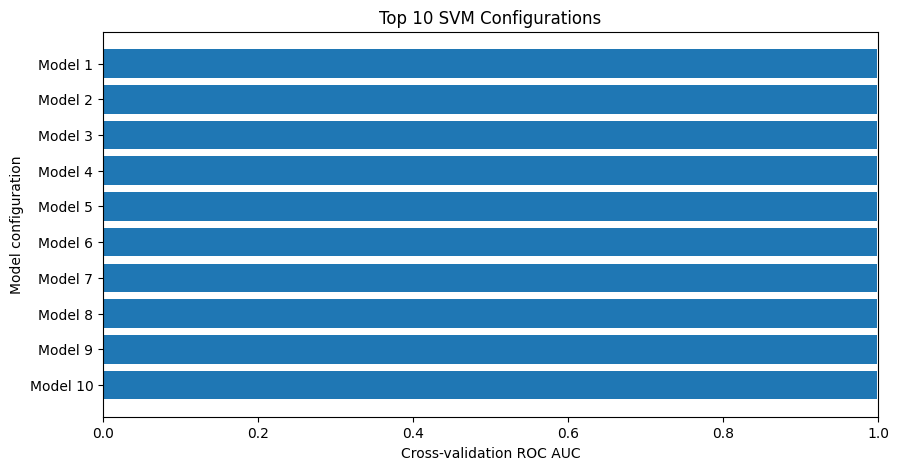

,param_svm__kernel,param_svm__C,param_svm__gamma,param_pca__n_components,mean_test_score,std_test_score
8,rbf,150,0.000165,100,0.998581,0.000892
7,rbf,100,0.000165,100,0.998581,0.000892
6,rbf,60,0.000165,100,0.998581,0.000892
5,rbf,30,0.000165,100,0.998581,0.000892
9,rbf,200,0.000165,100,0.998581,0.000892
2,rbf,100,0.000165,80,0.998431,0.000786
1,rbf,60,0.000165,80,0.998431,0.000786
0,rbf,30,0.000165,80,0.998431,0.000786
3,rbf,150,0.000165,80,0.998431,0.000786
4,rbf,200,0.000165,80,0.998431,0.000786


In [ ]:
import matplotlib.pyplot as plt

top_results = results_table.head(10).copy()

labels = [
    f"Model {i+1}"
    for i in range(len(top_results))
]

plt.figure(figsize=(10, 5))

plt.barh(
    labels[::-1],
    top_results["mean_test_score"].values[::-1]
)

plt.xlabel("Cross-validation ROC AUC")
plt.ylabel("Model configuration")
plt.title("Top 10 SVM Configurations")

plt.xlim(0, 1)
plt.show()

display(top_results)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from google.colab import files
import pandas as pd

# ===================================
# CHANGE THESE VALUES TO EXPERIMENT
# ===================================

MY_C = 150
MY_PCA = 100
MY_GAMMA = 0.000165

# ===================================
# BUILD YOUR SELECTED MODEL
# ===================================

my_model = Pipeline([
    ("scaler", StandardScaler()),

    ("pca", PCA(
        n_components=MY_PCA,
        svd_solver="randomized",
        random_state=42
    )),

    ("svm", SVC(
        kernel="rbf",
        C=MY_C,
        gamma=MY_GAMMA,
        probability=True,
        random_state=42
    ))
])

# Train on all 400 observations
my_model.fit(X, y)

# Predict probability of spoken seven (+1)
positive_class_index = list(
    my_model.classes_
).index(1)

probabilities = my_model.predict_proba(X_test)[
    :, positive_class_index
]

# Create Kaggle submission
submission = pd.DataFrame({
    "ID": test["ID"],
    "Probability": probabilities
})

# Save with unique filename
filename = f"submission_C{MY_C}_PCA{MY_PCA}.csv"

submission.to_csv(filename, index=False)

display(submission.head())

files.download(filename)

,ID,Probability
0,401,0.000622
1,402,0.000926
2,403,0.790029
3,404,0.598267
4,405,1.000000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>